# Pair 5. Restyle or anonymise a video clip (video editing)

**Business need:** reuse short clips (e.g. a person on campus) in teaching or marketing material without showing who the person is, or in a new visual style.

| | System A  | System B  |
|---|---|---|
| Model | **InstructPix2Pix, frame by frame** | **InstructPix2Pix + cross-frame attention** |
| How it works | Each frame is edited on its own (same seed every frame). The model has no idea the frames belong together | All frames are edited together, and every frame's self-attention uses **frame 1's keys and values** (the Text2Video-Zero trick) |
| Lecture link | Weeks 2-3 (image editing) | Weeks 6-7 (cross-frame attention for temporal consistency, training-free) |

**Why this is a fair test:** same model, same seed, same instruction. The **only** difference is the attention, so any difference in flicker is the measured value of temporal modelling.

In [1]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Use the lab GPU if there is one, otherwise the Mac's GPU ("mps"), otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Running on:", device)

import numpy as np
import imageio.v2 as imageio
from skimage.metrics import structural_similarity

Running on: cuda


In [2]:
# Download the two clips and keep 12 frames (every 10th/12th frame), saved as short 8 fps mp4s
import urllib.request

clips = {  # name: (url, keep every n-th frame)
    "walk.mp4": ("https://upload.wikimedia.org/wikipedia/commons/6/67/Dog_walking_in_the_Mission_in_San_Francisco.ogv", 10),
    "campus.mp4": ("https://upload.wikimedia.org/wikipedia/commons/1/1a/Linnanmaa_University_of_Oulu_20260118.webm", 12),
}
os.makedirs("data/p5_clips", exist_ok=True)
for name, (url, every_n) in clips.items():
    if not os.path.exists(f"data/p5_clips/{name}"):
        request = urllib.request.Request(url, headers={"User-Agent": "COMP8410 student coursework"})
        open("download.tmp", "wb").write(urllib.request.urlopen(request).read())
        frames = imageio.mimread("download.tmp", memtest=False)
        imageio.mimsave(f"data/p5_clips/{name}", frames[::every_n][:12], fps=8)
        os.remove("download.tmp")

In [3]:
os.makedirs("outputs/p5/A", exist_ok=True)
os.makedirs("outputs/p5/B", exist_ok=True)
os.makedirs("results/p5", exist_ok=True)

edits = pd.read_csv("data/p5_edits.csv")
N_FRAMES = 8          # keep it small: System B edits all frames at once, which needs memory
SIZE = 384


def read_frames(file):
    """The first N_FRAMES frames of a clip, as SIZE x SIZE PIL images."""
    frames = imageio.mimread(file, memtest=False)[:N_FRAMES]
    return [Image.fromarray(f).convert("RGB").resize((SIZE, SIZE)) for f in frames]


times_log = []
edits

,id,clip,instruction,target_text,purpose
0,k01,walk.mp4,turn the woman into a cartoon character,a cartoon character walking a dog on a city st...,anonymise
1,k02,walk.mp4,make it a watercolour painting,a watercolour painting of a woman walking a do...,restyle
2,k03,campus.mp4,make it a sunny summer afternoon with green trees,a university campus on a sunny summer afternoon,restyle
3,k04,campus.mp4,make it look like a pencil sketch,a pencil sketch of university campus buildings,restyle


## System A: InstructPix2Pix, one frame at a time

In [4]:
from diffusers import StableDiffusionInstructPix2PixPipeline

pipe = StableDiffusionInstructPix2PixPipeline.from_pretrained(
    "timbrooks/instruct-pix2pix", torch_dtype=torch.float16, safety_checker=None).to(device)

times_log = []     # each system keeps and saves its own times
for _, e in edits.iterrows():
    frames = read_frames(f"data/p5_clips/{e['clip']}")
    start = time.time()
    edited = []
    for frame in frames:
        generator = torch.Generator("cpu").manual_seed(0)       # the same seed for every frame
        edited.append(pipe(e["instruction"], image=frame, num_inference_steps=20,
                           image_guidance_scale=1.5, generator=generator).images[0])
    imageio.mimsave(f"outputs/p5/A/{e['id']}.mp4", [np.asarray(f) for f in edited], fps=8)
    times_log.append({"system": "A", "item": e["id"], "seconds": time.time() - start, "hand_minutes": 0})

pd.DataFrame(times_log).to_csv("results/p5/times_A.csv", index=False)

c:\Users\42075246\Desktop\Image Editing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1019 16:16:23.438000 24380 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
c:\Users\42075246\Desktop\Image Editing\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
100%|██████████| 20/20 [00:00<00:00, 35.85it/s]


## System B: the same model + cross-frame attention

`CrossFrameAttnProcessor` replaces the self-attention so every frame looks at **frame 1** (Week 6-7). `batch_size=3` because InstructPix2Pix runs three guidance branches (text, image, none) at once. Then all frames are passed in a single call.

In [5]:
from diffusers.pipelines.deprecated.text_to_video_synthesis.pipeline_text_to_video_zero import CrossFrameAttnProcessor

pipe.unet.set_attn_processor(CrossFrameAttnProcessor(batch_size=3))

times_log = []     # each system keeps and saves its own times
for _, e in edits.iterrows():
    frames = read_frames(f"data/p5_clips/{e['clip']}")
    start = time.time()
    generator = torch.Generator("cpu").manual_seed(0)
    edited = pipe([e["instruction"]] * len(frames), image=frames, num_inference_steps=20,
                  image_guidance_scale=1.5, generator=generator).images
    imageio.mimsave(f"outputs/p5/B/{e['id']}.mp4", [np.asarray(f) for f in edited], fps=8)
    times_log.append({"system": "B", "item": e["id"], "seconds": time.time() - start, "hand_minutes": 0})

pd.DataFrame(times_log).to_csv("results/p5/times_B.csv", index=False)

100%|██████████| 20/20 [00:03<00:00,  5.74it/s]


## Technical metrics

- **generated**: the edited clip exists.
- **clip_edit_gain**: how much closer the frames moved towards the target description (CLIP after − before).
- **ssim_structure**: average structural similarity between each original and edited frame (was the scene kept?).
- **extra_flicker**: how much *more* the edited clip changes between frames than the original clip did. Lower = steadier. This is the number that should show the difference between A and B.

In [6]:
# CLIP gives one number for "how well does this image match this text?"
# It is a proxy for quality, not a perfect judge, which is why human ratings are also collected.
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


def clip_score(image, text):
    """Similarity between an image and a text, x100. Higher = better match (typical range 15-35)."""
    inputs = clip_processor(text=[text], images=[image.convert("RGB")], return_tensors="pt", padding=True)
    with torch.no_grad():
        out = clip_model(**inputs)
    # image_embeds and text_embeds are already unit-length vectors, so the dot product is the cosine similarity
    return float((out.image_embeds[0] * out.text_embeds[0]).sum() * 100)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 28427.73it/s]


In [7]:
def ssim(image1, image2):
    a = np.asarray(image1.convert("L"), dtype=float) / 255
    b = np.asarray(image2.convert("L"), dtype=float) / 255
    return structural_similarity(a, b, data_range=1.0)


def flicker(frames):
    """Average absolute pixel change between neighbouring frames."""
    grey = [np.asarray(f.convert("L"), dtype=float) / 255 for f in frames]
    return np.mean([np.abs(grey[i + 1] - grey[i]).mean() for i in range(len(grey) - 1)])


rows = []
for _, e in edits.iterrows():
    original = read_frames(f"data/p5_clips/{e['clip']}")
    before = np.mean([clip_score(f, e["target_text"]) for f in original])
    for system in ["A", "B"]:
        file = f"outputs/p5/{system}/{e['id']}.mp4"
        row = {"system": system, "item": e["id"], "generated": int(os.path.exists(file))}
        if os.path.exists(file):
            edited = read_frames(file)
            row["clip_edit_gain"] = np.mean([clip_score(f, e["target_text"]) for f in edited]) - before
            row["ssim_structure"] = np.mean([ssim(a, b) for a, b in zip(original, edited)])
            row["extra_flicker"] = flicker(edited) - flicker(original)
        rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv("results/p5/metrics.csv", index=False)
summary = metrics.groupby("system")[["generated", "clip_edit_gain", "ssim_structure", "extra_flicker"]].mean()
summary

,generated,clip_edit_gain,ssim_structure,extra_flicker
system,,,,
A,1.0,2.093127,0.642942,0.014726
B,1.0,3.039799,0.660337,0.007359


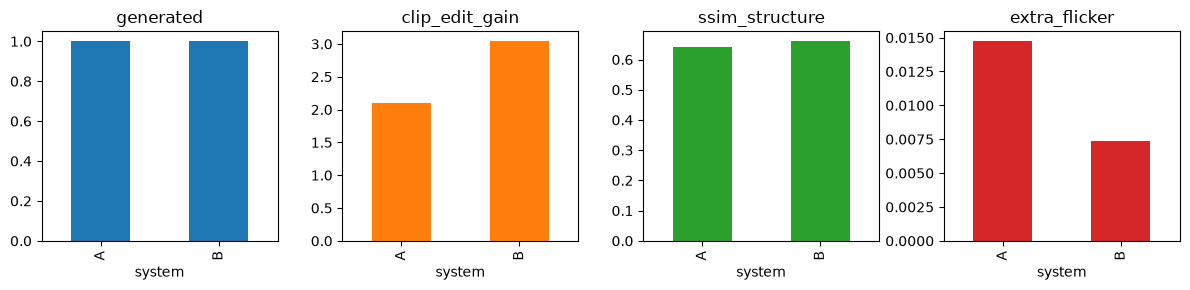

In [8]:
summary.plot(kind="bar", subplots=True, layout=(1, 4), figsize=(12, 3), legend=False)
plt.tight_layout()
plt.savefig("results/p5/metrics.png")

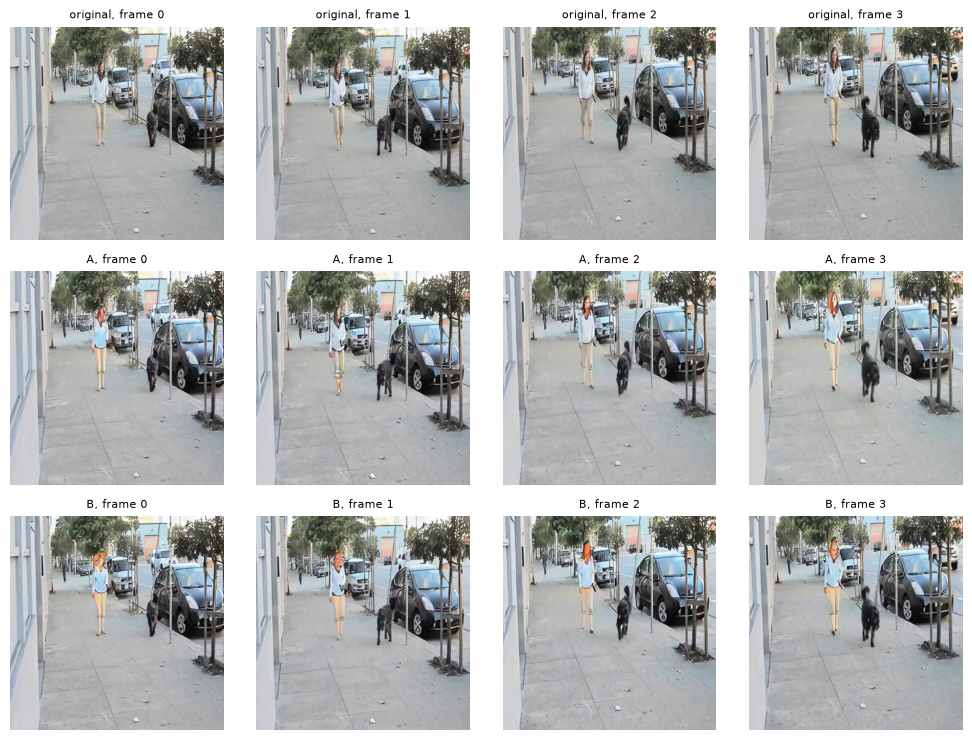

In [9]:
# Frames 1-4 of the first edit: original, System A, System B. Look for flicker in A.
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
rows_to_show = [("original", "data/p5_clips/walk.mp4"), ("A", "outputs/p5/A/k01.mp4"), ("B", "outputs/p5/B/k01.mp4")]
for r, (label, file) in enumerate(rows_to_show):
    for c, frame in enumerate(read_frames(file)[:4]):
        axes[r, c].imshow(frame)
        axes[r, c].set_title(f"{label}, frame {c}", fontsize=8)
        axes[r, c].axis("off")
plt.tight_layout()